# EDA: цены газа и карбамида (World Bank Pink Sheet)

**Вопрос этого ноутбука:** есть ли в надбавке цены карбамида к газовой себестоимости предсказуемая часть и что её двигает?

**Логика проекта:** цена карбамида = газовая себестоимость + надбавка. Себестоимость считаем по формуле `k × цена газа`, надбавку прогнозирует модель. Чтобы такой подход имел смысл, нужно показать на данных:
1. газ действительно связан с ценой карбамида и влияет на неё с понятным отставанием;
2. надбавка, в отличие от самой цены, возвращается к среднему (стационарна);
3. у надбавки есть «память» на горизонте 1–3 месяца, который мы прогнозируем.

**Перед запуском:** из корня репозитория выполни `python src/data/load_pink_sheet.py` — он создаст `data/processed/prices_monthly.parquet` из файла World Bank в `data/raw/`.

**Период анализа — с апреля 2015 года.** Лист `Description` файла World Bank: газ Европы считается по хабу TTF только с апреля 2015, а раньше — как средняя импортная цена на границе. Это два разных показателя, склеивать их в одну себестоимость нельзя.

Вторая смена методики — у карбамида: с марта 2022 это цена FOB Ближний Восток, раньше — FOB Чёрное море. Её не обойти (она в середине ряда), поэтому только помечаем на графиках.

## 0. Загрузка и производные переменные

- `gas_cost` — газовая себестоимость тонны карбамида, $/т: `k × gas_europe`. k = 26 млн БТЕ/т — предварительная оценка расхода газа (уточняет Владислав по балансам производства).
- `markup` — надбавка, $/т: цена минус газовая себестоимость. Это то, что будет прогнозировать модель.
- `r_urea`, `r_gas` — лог-приращения цен, ≈ изменение в % за месяц. Связи между рядами проверяем на изменениях, а не на уровнях: два растущих ряда «коррелируют» даже без реальной связи (ложная регрессия).
- `d_markup` — изменение надбавки за месяц, $/т (у надбавки логарифм не берём: она бывает отрицательной).

In [21]:
import numpy as np                                   # математика
import pandas as pd                                  # таблицы
import matplotlib.pyplot as plt                      # графики

df = pd.read_parquet("../data/processed/prices_monthly.parquet")   # ноутбук лежит в notebooks/, поэтому ../

K = 26                       # расход газа на тонну карбамида, млн БТЕ/т (предварительно, уточняет Владислав)
START = "2015-04"            # с апреля 2015 газ Европы = TTF

df["gas_cost"] = K * df["gas_europe"]                     # газовая себестоимость, $/т
df["markup"] = df["urea_price"] - df["gas_cost"]          # надбавка, $/т
df["r_urea"] = np.log(df["urea_price"]).diff()            # лог-приращение цены карбамида (≈ % за месяц)
df["r_gas"] = np.log(df["gas_europe"]).diff()             # лог-приращение цены газа
df["d_markup"] = df["markup"].diff()                      # изменение надбавки за месяц, $/т

s = df.loc[START:]                                        # рабочий период
print(len(s), "месяцев:", s.index.min().date(), "—", s.index.max().date())
s[["urea_price", "gas_europe", "markup"]].describe().round(1)

138 месяцев: 2015-04-01 — 2026-09-01


,urea_price,gas_europe,markup
count,138.0,138.0,138.0
mean,351.7,11.8,44.5
std,174.0,11.1,187.9
min,142.6,1.6,-1229.7
25%,233.8,5.2,36.6
50%,286.2,8.0,83.8
75%,394.5,13.2,117.5
max,925.0,70.0,456.2


**Вывод.** 138 месяцев (апрель 2015 – сентябрь 2026), пропусков нет. Медиана надбавки $84/т, но разброс огромный: от −$1230 (август 2022) до +$456 (апрель 2026). Значит, в данных есть «обычный» режим и резкие кризисы — это важно для всего дальнейшего анализа.

## 1. Газ в трёх регионах

**Зачем:** выбрать, по какому газу считать себестоимость, и увидеть, что газ — не единый мировой товар (его дорого перевозить, поэтому цены в регионах разные).

**Как читать:** смотрим, насколько расходятся линии и когда. Пунктир — апрель 2015, смена методики газа Европы (не рыночное событие).

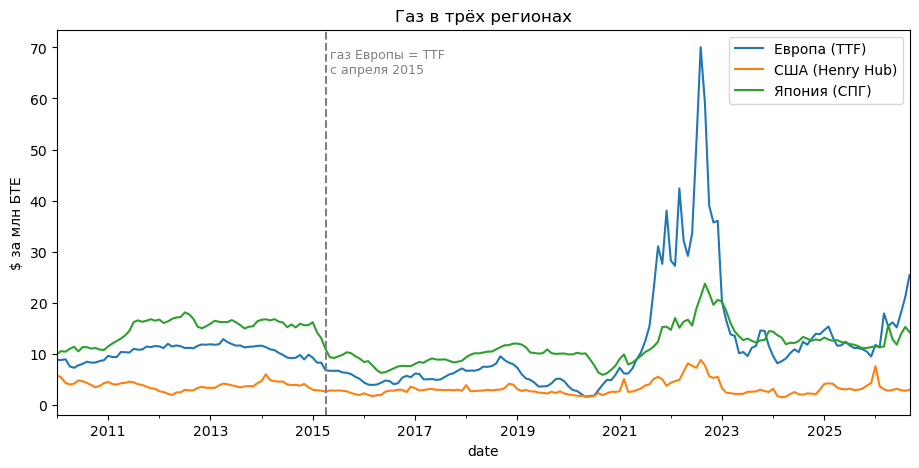

In [22]:
ax = df.loc["2010":, ["gas_europe", "gas_us", "lng_japan"]].plot(figsize=(11, 5))
ax.axvline(pd.Timestamp("2015-04-01"), color="grey", linestyle="--")                      # с этого месяца газ Европы = TTF
ax.text(pd.Timestamp("2015-04-01"), 65, " газ Европы = TTF\n с апреля 2015", fontsize=9, color="grey")
ax.set_ylabel("$ за млн БТЕ")
ax.legend(["Европа (TTF)", "США (Henry Hub)", "Япония (СПГ)"])
ax.set_title("Газ в трёх регионах")
plt.show()

**Вывод.**
- До 2021 года все три цены в пределах ~$2–18. В 2022 году газ в Европе взлетает до $70, в США остаётся ~$5–9, в Японии ~$24. В 2026 году Европа снова растёт (до $25), США — около $3.
- Рынки газа разделены, себестоимость производителей в разных странах отличается в разы (Европа бывала дороже США до 10 раз).
- Резкое падение Японии и Европы в 2015 году — реальное падение рынка вслед за нефтью (цена СПГ Японии в основном привязана к нефти), а не смена методики.

**Что это даёт:** европейский газ — самый дорогой и волатильный, именно он задаёт себестоимость «последнего» производителя. Берём его для формулы (выбор подтверждают тесты в разделе 7).

## 2. Цена карбамида и газовая себестоимость

**Зачем:** проверить главную идею проекта — цена = себестоимость + надбавка.

**Как читать:** обе линии в $/т на одной оси. Промежуток между ними — надбавка: цена выше себестоимости — надбавка положительная, ниже — отрицательная. Пунктиры: апрель 2015 (газ = TTF) и март 2022 (карбамид: Чёрное море → Ближний Восток).

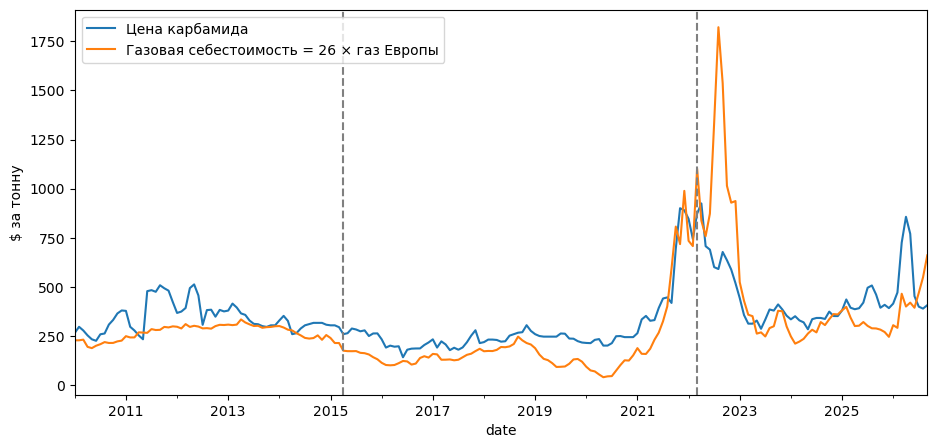

In [23]:
ax = df.loc["2010":, ["urea_price", "gas_cost"]].plot(figsize=(11, 5))
ax.axvline(pd.Timestamp("2015-04-01"), color="grey", linestyle="--")      # газ = TTF
ax.axvline(pd.Timestamp("2022-03-01"), color="grey", linestyle="--")      # карбамид: Чёрное море -> Ближний Восток
ax.set_ylabel("$ за тонну")
ax.legend(["Цена карбамида", f"Газовая себестоимость = {K} × газ Европы"])
plt.show()

**Вывод.**
- 2015–2021: цена стабильно чуть выше себестоимости — газ задаёт уровень цены, надбавка небольшая и ровная.
- 2022: себестоимость по TTF доходит до ~$1800/т, а цена не поднимается выше ~$700. Европейские заводы в такой ситуации сокращают выпуск, и цену задают производители с дешёвым газом.
- 2026: в марте – мае цена резко выше себестоимости (шок предложения из-за Ормуза), к сентябрю — снова ниже (TTF растёт, карбамид дешевеет).

**Что это даёт:** формула `k × TTF` хорошо работает в спокойное время и завышает себестоимость в газовые кризисы. Вопрос к команде: нужен признак режима (например, разница TTF и Henry Hub) или другое определение себестоимости.

## 3. Надбавка: среднее и разброс за 12 месяцев

**Зачем:** проверить стационарность «на глаз». Стационарный ряд держит среднее и разброс примерно на одном уровне, а не уходит в тренд.

**Как читать:** скользящее среднее — среднее надбавки за последние 12 месяцев в каждой точке; скользящий разброс — стандартное отклонение за те же 12 месяцев. Ниже нуля — цена ниже газовой себестоимости.

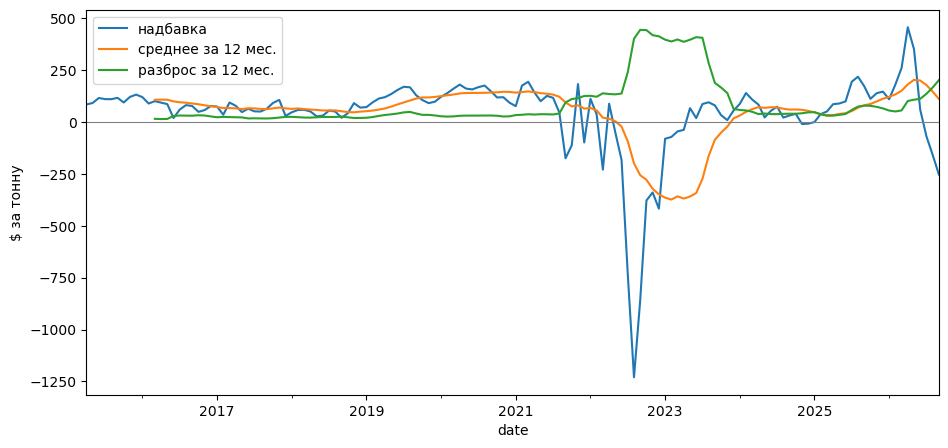

In [24]:
ax = s["markup"].plot(figsize=(11, 5), label="надбавка")
s["markup"].rolling(12).mean().plot(ax=ax, label="среднее за 12 мес.")     # скользящее среднее
s["markup"].rolling(12).std().plot(ax=ax, label="разброс за 12 мес.")      # скользящее стандартное отклонение
ax.axhline(0, color="grey", linewidth=0.8)                                 # ниже нуля — цена ниже себестоимости
ax.set_ylabel("$ за тонну")
ax.legend()
plt.show()

**Вывод.**
- 2015–2021: надбавка ровная, ~$50–150/т, разброс маленький.
- 2021–2023: провал до −$1230, скользящее среднее уходит до ~−$350, разброс растёт примерно с $30 до $440.
- С 2023 года — снова спокойно; в 2026 году — новый всплеск и падение.

**Что это даёт:**
- у надбавки есть «нормальный уровень», к которому она возвращается — хороший знак для прогноза;
- но разброс непостоянен, кризисы — отдельный режим. Ошибку модели (MSPE) считаем отдельно для спокойных и кризисных месяцев, иначе один 2022 год задавит всю статистику.

## 4. Сезонность

**Зачем:** понять, нужны ли модели сезонные признаки (`month_sin` / `month_cos`) и сезонная часть в SARIMA. Спрос на удобрения зависит от посевной, поэтому сезонность возможна.

**Как читать:**
- STL раскладывает надбавку на четыре панели: исходный ряд, тренд, сезонность (повторяющийся годовой узор) и остаток. Сравниваем размах сезонной панели с размахом остатка.
- Столбики — медианное изменение цены карбамида в каждом месяце года (1 = январь). Медиана, а не среднее, чтобы один кризисный месяц не исказил картину.

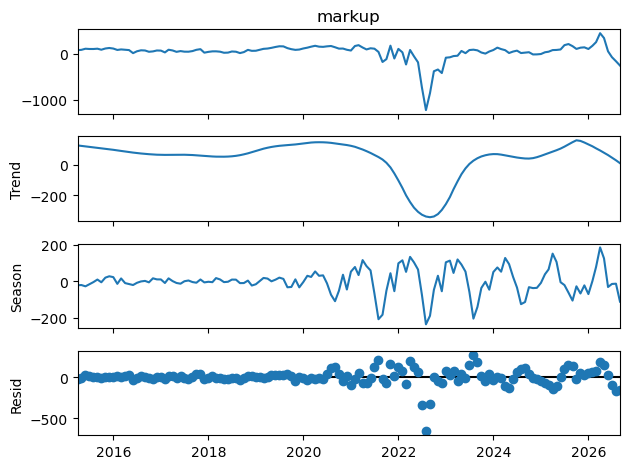

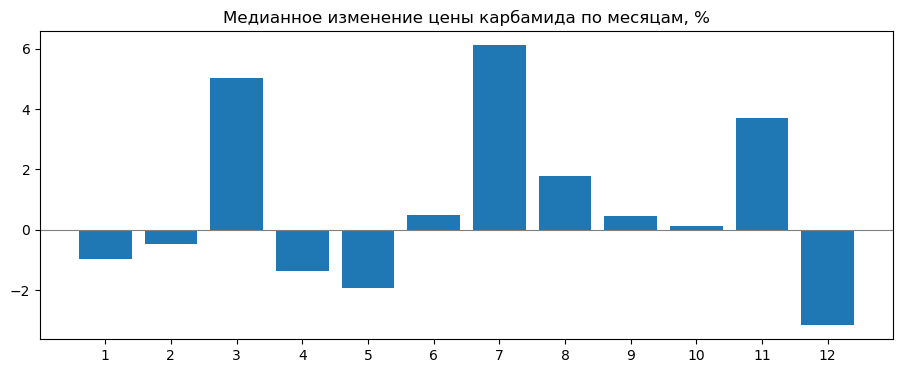

In [25]:
from statsmodels.tsa.seasonal import STL

STL(s["markup"], period=12).fit().plot()               # period=12 — годовая сезонность на месячных данных
plt.show()

by_month = s["r_urea"].groupby(s.index.month).median() * 100   # медианное изменение цены по месяцам, %
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(by_month.index, by_month.values)                 # столбик на каждый месяц
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_title("Медианное изменение цены карбамида по месяцам, %")
plt.show()

**Вывод.**
- STL: до 2021 года сезонная часть крошечная (±$20). После 2021 года её колебания вырастают до ±$200 и становятся неровными — это не настоящая сезонность, STL «размазывает» кризисные скачки по сезонной части. Остатки огромные в 2022 году.
- Медианы: март +5%, июль +6%, ноябрь +4%, декабрь −3%. Но на каждый месяц всего 11–12 наблюдений, и картина шумная.

**Что это даёт:** сезонность слабая и ненадёжная. Сезонную часть SARIMA можно не добавлять; `month_sin` / `month_cos` оставляем кандидатами на отбор признаков — если не улучшат MSPE на валидации, убираем.

## 5. Автокорреляция надбавки (ACF, PACF)

**Зачем:** узнать, есть ли у надбавки «память» — помогает ли значение прошлых месяцев предсказать следующий, и сколько прошлых месяцев брать в признаки.

**Как читать:**
- ACF (автокорреляция) — корреляция надбавки с самой собой k месяцев назад. Голубая полоса — граница случайности: столбики за ней значимы. Быстрое затухание = ряд возвращается к среднему; очень медленное (0,95; 0,93…) = похоже на нестационарный ряд.
- PACF (частная автокорреляция) — то же, но без влияния промежуточных лагов: сколько добавляет лаг k сверх лагов 1…k−1. Где PACF обрывается — подсказка для порядка AR(p) в ARIMA.
- Третий график — ACF изменений надбавки.

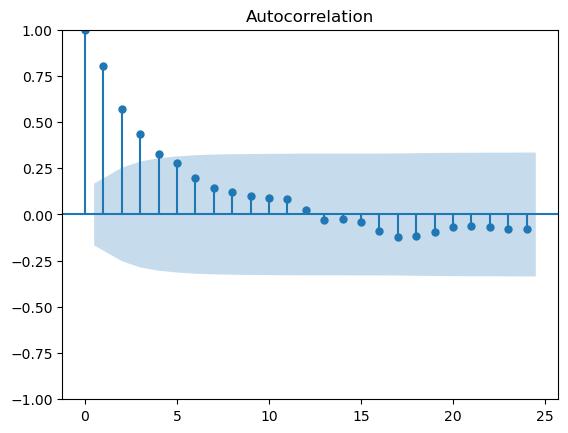

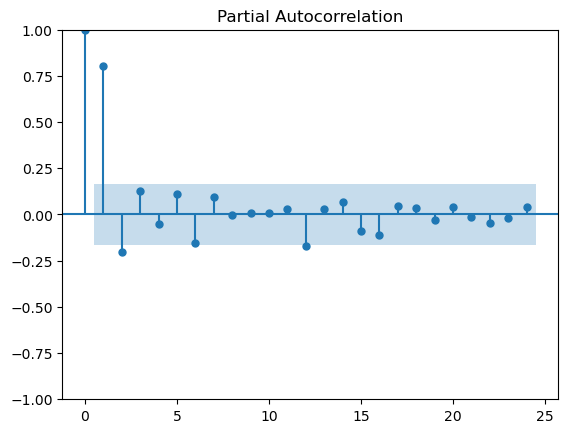

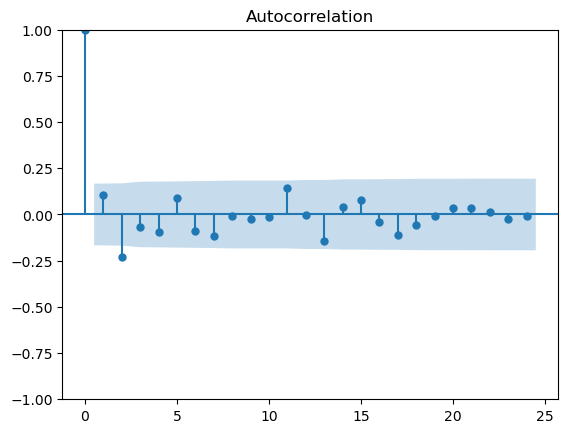

In [26]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(s["markup"], lags=24)                         # корреляция надбавки с собой k месяцев назад
plot_pacf(s["markup"], lags=24)                        # то же без влияния промежуточных лагов
plot_acf(s["d_markup"].dropna(), lags=24)              # для изменений надбавки
plt.show()

**Вывод.**
- ACF надбавки: 0,81 → 0,58 → 0,44 и плавно затухает, к 7–8-му месяцу внутри полосы. Это геометрическое затухание — типичная картина стационарного ряда с памятью.
- PACF: огромный пик на лаге 1 (≈0,8), небольшой значимый отрицательный на лаге 2 (≈−0,2), остальные почти все внутри полосы.
- ACF изменений надбавки: значим только лаг 2 (≈−0,23) — после скачка через два месяца часть его откатывается.

**Что это даёт:**
- надбавку хорошо описывает AR(1)–AR(2): «следующий месяц ≈ 0,8 × текущее отклонение от нормы»;
- в признаки обязательно `markup_lag1` и `markup_lag2`, дальние лаги почти ничего не добавят;
- база для ARIMA: начинать с AR(1) или AR(2) по уровню надбавки.

## 6. С каким отставанием газ влияет на карбамид

**Зачем:** ответить на вопрос куратора — через сколько месяцев изменение цены газа отражается в цене карбамида.

**Как читать:** столбик k — корреляция изменения цены карбамида в месяц t с изменением газа в месяц t − k. Пунктир — граница случайности ≈ ±2/√n: столбики выше неё значимы.

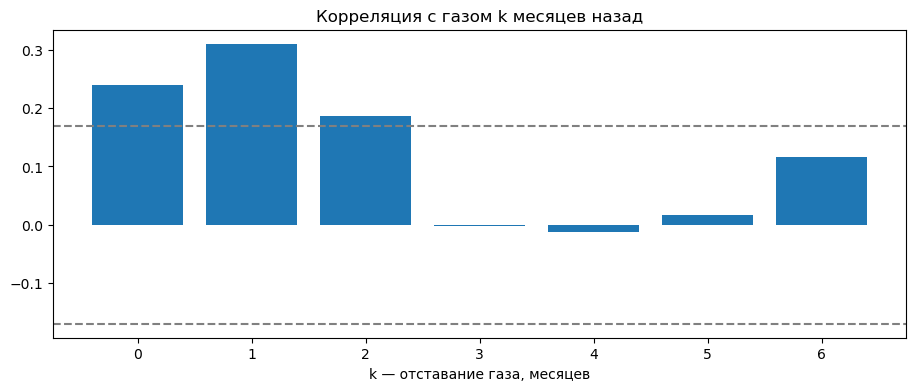

0    0.241
1    0.311
2    0.187
3   -0.002
4   -0.012
5    0.017
6    0.117
dtype: float64

In [27]:
lags = range(0, 7)
ccf = pd.Series([s["r_urea"].corr(s["r_gas"].shift(k)) for k in lags], index=list(lags))   # газ сдвинут на k месяцев назад
band = 2 / np.sqrt(s["r_urea"].notna().sum())                                             # граница случайности

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(ccf.index, ccf.values)                            # столбик на каждое отставание k
ax.set_xlabel("k — отставание газа, месяцев")
ax.set_title("Корреляция с газом k месяцев назад")
ax.axhline(band, color="grey", linestyle="--")
ax.axhline(-band, color="grey", linestyle="--")
plt.show()
ccf.round(3)

**Вывод.** Корреляции 0,24 / 0,31 / 0,19 на лагах 0 / 1 / 2 — все выше границы (≈0,17); с лага 3 — около нуля.

**Что это даёт:** изменение газа отражается в цене карбамида сразу и сильнее всего — через месяц, а через три месяца эффект исчезает. Признаки: изменение газа за текущий месяц и 1–2 месяца назад. Это ещё одно подтверждение горизонта 1–3 месяца.

## 7. Тесты стационарности: ADF и KPSS

**Зачем:** числом проверить, что прогнозировать надбавку разумнее, чем саму цену. Стационарный ряд возвращается к среднему — у модели есть что ловить; нестационарный блуждает — лучший прогноз почти всегда «как в прошлом месяце».

**Как читать:** у тестов противоположные нулевые гипотезы, поэтому если оба говорят одно и то же — вывод надёжный.
- ADF: нулевая гипотеза — ряд **нестационарен**. p < 0,05 → стационарен.
- KPSS: нулевая гипотеза — ряд **стационарен**. p < 0,05 → нестационарен. KPSS показывает p не больше 0,10: дальше его таблица не идёт, 0,10 означает «p ≥ 0,10».

In [28]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")                       # KPSS предупреждает, когда p-value за пределами таблицы

rows = []
for col in ["urea_price", "markup", "r_urea", "d_markup"]:
    x = s[col].dropna()
    adf_t, adf_p, *_ = adfuller(x, autolag="AIC")       # AIC сам выбирает число лагов
    kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
    rows.append({"ряд": col, "ADF t": round(adf_t, 2), "ADF p": round(adf_p, 3), "KPSS p": round(kpss_p, 3)})

# устойчивость: надбавка без кризиса 2021–2022
x = s["markup"][(s.index < "2021-01-01") | (s.index > "2022-12-01")]
adf_t, adf_p, *_ = adfuller(x, autolag="AIC")
rows.append({"ряд": "markup без 2021–2022", "ADF t": round(adf_t, 2), "ADF p": round(adf_p, 3), "KPSS p": None})

# какой газ брать: надбавка по газу США и отношение цена/газ Европы
for name, x in [("надбавка по газу США", s["urea_price"] - K * s["gas_us"]),
                ("отношение цена / газ Европы", s["urea_price"] / s["gas_europe"])]:
    adf_t, adf_p, *_ = adfuller(x.dropna(), autolag="AIC")
    rows.append({"ряд": name, "ADF t": round(adf_t, 2), "ADF p": round(adf_p, 3), "KPSS p": None})

pd.DataFrame(rows)

,ряд,ADF t,ADF p,KPSS p
0,urea_price,-2.38,0.148,0.01
1,markup,-3.42,0.010,0.10
2,r_urea,-2.88,0.048,0.10
3,d_markup,-5.73,0.000,0.10
4,markup без 2021–2022,-3.85,0.002,NaN
5,надбавка по газу США,-2.47,0.124,NaN
6,отношение цена / газ Европы,-1.79,0.387,NaN


**Вывод** (результаты запуска от 17 октября 2026 года, данные World Bank от 2 октября 2026):

| Ряд | ADF p | KPSS p | Вывод |
|---|---|---|---|
| цена карбамида | 0,148 | 0,01 | оба теста: **нестационарна** |
| надбавка | 0,010 | ≥ 0,10 | оба теста: **стационарна** |
| изменение цены | 0,048 | ≥ 0,10 | стационарно (ADF на грани) |
| изменение надбавки | 0,000 | ≥ 0,10 | стационарно |
| надбавка без 2021–2022 | 0,002 | — | стационарна ещё увереннее |

Строки «надбавка по газу США» (ADF p = 0,124) и «отношение цена / газ Европы» (p = 0,387) — сравнение вариантов себестоимости: оба нестационарны. Стационарна только надбавка по газу Европы (TTF), поэтому для формулы себестоимости берём его.

**Что это даёт:** главное подтверждение подхода. Цена блуждает — поэтому наивный прогноз цены так трудно обогнать. Надбавка по газу Европы возвращается к среднему — у модели есть что ловить. Выбор целевой переменной обоснован данными, и вывод держится даже без кризисных лет.

## 8. Полураспад надбавки

**Зачем:** перевести «возвращается к среднему» в понятное число — за сколько месяцев отклонение надбавки от нормы сокращается вдвое.

**Как читать:** полураспад = ln(0,5) / ln(φ), где φ — автокорреляция на лаге 1. φ = 0,8 → ~3 месяца; φ = 0,95 → ~13,5 месяца.

In [29]:
phi = s["markup"].autocorr(lag=1)
print("phi =", round(phi, 2), "| полураспад, мес. =", round(np.log(0.5) / np.log(phi), 1))

phi = 0.81 | полураспад, мес. = 3.3


**Вывод.** φ = 0,81, полураспад 3,3 месяца.

**Что это даёт:** горизонт прогноза 1–3 месяца ровно попадает в окно, где возврат к среднему уже идёт, но ещё не закончился. На горизонте 12 месяцев модель предсказывала бы почти просто среднее.

## 9. Тест Грейнджера

**Зачем:** проверить, что прошлое газа помогает предсказать карбамид сверх прошлого самого карбамида — и что связь идёт в правильную сторону (газ → карбамид, а не наоборот).

**Как читать:** нулевая гипотеза — прошлое второго ряда не помогает прогнозу первого. p < 0,05 → помогает. Это не «причинность» в бытовом смысле, а именно полезность для прогноза — то, что нам нужно. Тест работает на стационарных рядах, поэтому берём лог-приращения.

In [30]:
from statsmodels.tsa.stattools import grangercausalitytests

def granger_p(target, cause, maxlag=6):
    data = s[[target, cause]].dropna()                   # первая колонка — что предсказываем, вторая — чем
    res = grangercausalitytests(data, maxlag=maxlag, verbose=False)
    return {lag: round(res[lag][0]["ssr_ftest"][1], 3) for lag in range(1, maxlag + 1)}

print("газ -> карбамид:", granger_p("r_urea", "r_gas"))
print("карбамид -> газ:", granger_p("r_gas", "r_urea"))   # обратная проверка: должна быть незначима

газ -> карбамид: {1: 0.001, 2: 0.001, 3: 0.001, 4: 0.005, 5: 0.011, 6: 0.002}
карбамид -> газ: {1: 0.537, 2: 0.291, 3: 0.357, 4: 0.344, 5: 0.311, 6: 0.278}


**Вывод.** Газ → карбамид: p = 0,001–0,011 на всех лагах 1–6, связь значима. Карбамид → газ: p = 0,28–0,54, связи нет.

**Что это даёт:** прошлое газа содержит информацию о будущей цене карбамида, которой нет в самой цене. Связь односторонняя, как и должно быть по экономике. Это оправдывает газ как признак и всю конструкцию с себестоимостью.

## Итог: что мы получили для модели

1. **Целевая переменная — надбавка.** Она стационарна (ADF и KPSS согласны), в отличие от цены. Выбор подтверждён данными.
2. **Горизонт 1–3 месяца подтверждён дважды:** полураспад надбавки 3,3 месяца, влияние газа длится 0–2 месяца.
3. **Признаки:** `markup_lag1`, `markup_lag2`, изменение газа с лагами 0–2. Сезонность — только кандидат на отбор.
4. **Бейзлайн-модель:** AR(1)–AR(2) по надбавке; сезонная часть SARIMA, скорее всего, не нужна.
5. **Газ для себестоимости — Европа (TTF):** только с ним надбавка стационарна.
6. **Риски:**
   - кризисы — отдельный режим с огромным разбросом: качество модели оцениваем отдельно на спокойных и кризисных месяцах;
   - формула `k × TTF` завышает себестоимость, когда газ в Европе очень дорог (2022, июль – сентябрь 2026) — возможен признак режима (разница TTF и Henry Hub);
   - смена площадки карбамида в марте 2022 — отмечаем в отчёте.

**Открытые вопросы к созвону:** признак режима газа или другое определение себестоимости? Как отразить смену площадки карбамида: дамми или достаточно оговорки? Уточнённое значение k от Владислава.

In [31]:
from statsmodels.tsa.stattools import adfuller            # тест ADF

x = df.loc["2010":, "markup"].dropna()                     # надбавка с 2010 года (до апреля 2015 газ Европы ещё не TTF)
adf_t, adf_p, *_ = adfuller(x, autolag="AIC")              # AIC сам выбирает число лагов
print("ADF с 2010 года: t =", round(adf_t, 2), "| p =", round(adf_p, 3))

ADF с 2010 года: t = -3.53 | p = 0.007
